This code for custom binning is based on the instruction provided by 10x genomics: https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd

Note, that the cell segmentation is performed using the python script NucleiSegmentation.py


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import anndata
import geopandas as gpd
import scanpy as sc
import pickle
import os
import gc

from tifffile import imread, imwrite
from csbdeep.utils import normalize
from stardist.models import StarDist2D
from shapely.geometry import Polygon, Point
from scipy import sparse
from matplotlib.colors import ListedColormap

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
2025-10-29 20:28:00.440587: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-10-29 20:28:00.704314: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorF

# Data Visualisation Helper Functions

We define functions to help with plotting results in the next code block.

In [ ]:
# General image plotting functions
def plot_mask_and_save_image(title, gdf, img, cmap, output_name=None, bbox=None):
    if bbox is not None:
        # Crop the image to the bounding box
        cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]
    else:
        cropped_img = img

    # Plot options
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot the cropped image
    axes[0].imshow(cropped_img, cmap='gray', origin='lower')
    axes[0].set_title(title)
    axes[0].axis('off')

    # Create filtering polygon
    if bbox is not None:
        bbox_polygon = Polygon([(bbox[0], bbox[1]), (bbox[2], bbox[1]), (bbox[2], bbox[3]), (bbox[0], bbox[3])])
        # Filter for polygons in the box
        intersects_bbox = gdf['geometry'].intersects(bbox_polygon)
        filtered_gdf = gdf[intersects_bbox]
    else:
        filtered_gdf=gdf

    # Plot the filtered polygons on the second axis
    filtered_gdf.plot(cmap=cmap, ax=axes[1])
    axes[1].axis('off')
    axes[1].legend(loc='upper left', bbox_to_anchor=(1.05, 1))


    # Save the plot if output_name is provided
    if output_name is not None:
        plt.savefig(output_name, bbox_inches='tight')  # Use bbox_inches='tight' to include the legend
    else:
        plt.show()

def plot_gene_and_save_image(title, gdf, gene, img, adata, bbox=None, output_name=None):

    if bbox is not None:
        # Crop the image to the bounding box
        cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]
    else:
        cropped_img = img

    # Plot options
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot the cropped image
    axes[0].imshow(cropped_img, cmap='gray', origin='lower')
    axes[0].set_title(title)
    axes[0].axis('off')

    # Create filtering polygon
    if bbox is not None:
        bbox_polygon = Polygon([(bbox[0], bbox[1]), (bbox[2], bbox[1]), (bbox[2], bbox[3]), (bbox[0], bbox[3])])


    # Find a gene of interest and merge with the geodataframe
    gene_expression = adata[:, gene].to_df()
    gene_expression['id'] = gene_expression.index
    merged_gdf = gdf.merge(gene_expression, left_on='id', right_on='id')

    if bbox is not None:
        # Filter for polygons in the box
        intersects_bbox = merged_gdf['geometry'].intersects(bbox_polygon)
        filtered_gdf = merged_gdf[intersects_bbox]
    else:
        filtered_gdf = merged_gdf

    # Plot the filtered polygons on the second axis
    filtered_gdf.plot(column=gene, cmap='inferno', legend=True, ax=axes[1])
    axes[1].set_title(gene)
    axes[1].axis('off')
    axes[1].legend(loc='upper left', bbox_to_anchor=(1.05, 1))

    # Save the plot if output_name is provided
    if output_name is not None:
        plt.savefig(output_name, bbox_inches='tight')  # Use bbox_inches='tight' to include the legend
    else:
        plt.show()

def plot_clusters_and_save_image(title, gdf, img, adata, bbox=None, color_by_obs=None, output_name=None, color_list=None):
    color_list=["#7f0000","#808000","#483d8b","#008000","#bc8f8f","#008b8b","#4682b4","#000080","#d2691e","#9acd32","#8fbc8f","#800080","#b03060","#ff4500","#ffa500","#ffff00","#00ff00","#8a2be2","#00ff7f","#dc143c","#00ffff","#0000ff","#ff00ff","#1e90ff","#f0e68c","#90ee90","#add8e6","#ff1493","#7b68ee","#ee82ee"]
    if bbox is not None:
        cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]
    else:
        cropped_img = img

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(cropped_img, cmap='gray', origin='lower')
    axes[0].set_title(title)
    axes[0].axis('off')

    if bbox is not None:
        bbox_polygon = Polygon([(bbox[0], bbox[1]), (bbox[2], bbox[1]), (bbox[2], bbox[3]), (bbox[0], bbox[3])])

    unique_values = adata.obs[color_by_obs].astype('category').cat.categories
    num_categories = len(unique_values)

    if color_list is not None and len(color_list) >= num_categories:
        custom_cmap = ListedColormap(color_list[:num_categories], name='custom_cmap')
    else:
        # Use default tab20 colors if color_list is insufficient
        tab20_colors = plt.cm.tab20.colors[:num_categories]
        custom_cmap = ListedColormap(tab20_colors, name='custom_tab20_cmap')

    merged_gdf = gdf.merge(adata.obs[color_by_obs].astype('category'), left_on='id', right_index=True)

    if bbox is not None:
        intersects_bbox = merged_gdf['geometry'].intersects(bbox_polygon)
        filtered_gdf = merged_gdf[intersects_bbox]
    else:
        filtered_gdf = merged_gdf

    # Plot the filtered polygons on the second axis
    plot = filtered_gdf.plot(column=color_by_obs, cmap=custom_cmap, ax=axes[1], legend=True)
    axes[1].set_title(color_by_obs)
    legend = axes[1].get_legend()
    legend.set_bbox_to_anchor((1.05, 1))
    axes[1].axis('off')

    # Move legend outside the plot
    plot.get_legend().set_bbox_to_anchor((1.25, 1))

    if output_name is not None:
        plt.savefig(output_name, bbox_inches='tight')
    else:
        plt.show()

# Plotting function for nuclei area distribution
def plot_nuclei_area(gdf,area_cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(15, 4))
    # Plot the histograms
    axs[0].hist(gdf['area'], bins=50, edgecolor='black')
    axs[0].set_title('Nuclei Area')

    axs[1].hist(gdf[gdf['area'] < area_cut_off]['area'], bins=50, edgecolor='black')
    axs[1].set_title('Nuclei Area Filtered:'+str(area_cut_off))

    plt.tight_layout()
    plt.show()

# Total UMI distribution plotting function
def total_umi(adata_, cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # Box plot
    axs[0].boxplot(adata_.obs["total_counts"], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[0].set_title('Total Counts')

    # Box plot after filtering
    axs[1].boxplot(adata_.obs["total_counts"][adata_.obs["total_counts"] > cut_off], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[1].set_title('Total Counts > ' + str(cut_off))

    # Remove y-axis ticks and labels
    for ax in axs:
        ax.get_yaxis().set_visible(False)

    plt.tight_layout()
    plt.show()


In [4]:
person = "CRC_P2"  # Adapt to requirements
bin_size = "002um"
dir_base_output = f"../data/{person}/output/binned_outputs/square_{bin_size}"
dir_result_output = f"output/{person}/{bin_size}/custom_binning"
os.makedirs(dir_result_output, exist_ok=True)

dir_base_input = f'../data/{person}/input/'  # Adjust this path as needed
filename = 'Visium_HD_Human_Colon_Cancer_P2_tissue_image.btf'  # Adjust this filename as needed

**Note**
Only run the next cell if you want to process the entire high res image. Note that this requires a lot of RAM. 
In the cell after this, you should then uncomment the last line:
`#plot_mask_and_save_image(title="Region of Interest 1",...,output_name=dir_base+"image_mask.ROI1.tif")
`

In [ ]:
# Load the image file
# Change dir_base as needed to the directory where the downloaded example data is stored
img = imread(dir_base_input + filename)

# Load the pretrained model
# model = StarDist2D.from_pretrained('2D_versatile_he')

# Percentile normalization of the image
# Adjust min_percentile and max_percentile as needed
min_percentile = 5
max_percentile = 95
img = normalize(img, min_percentile, max_percentile)

The following code plots a region of interest from the polygons. 
We can extract the min and max positions from the tissue positions.
In the provided code, the bounding box argument (bbox) is entered as <code>(x min, y min, x max, y max)</code>.

In [9]:
# Plot the nucleus segmentation
# bbox=(x min,y min,x max,y max)
import math
import os

tissue_path = os.path.join(dir_base_output, "spatial", "tissue_positions.parquet") # stores ID for each bin, bin coordinates in pixel and array format
tissuepositions = pd.read_parquet(tissue_path)
col = "pxl_col_in_fullres"
row = "pxl_row_in_fullres"
x_min = math.floor(tissuepositions.loc[tissuepositions[col] > 0, col].min())
x_max = math.ceil(tissuepositions.loc[tissuepositions[col] > 0, col].max())
y_min = math.floor(tissuepositions.loc[tissuepositions[row] > 0, row].min())
y_max = math.ceil(tissuepositions.loc[tissuepositions[row] > 0, row].max())
#tissuepositions.close()

# Load the saved polys dictionary
with open(f"output/{person}/{bin_size}/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

# Reconstruct the geometries from the coordinate data
geometries = []
for nuclei in range(len(polys['coord'])):
    coords = [(y, x) for x, y in zip(polys['coord'][nuclei][0], polys['coord'][nuclei][1])]
    geometries.append(Polygon(coords))

# Create the GeoDataFrame
gdf = gpd.GeoDataFrame(geometry=geometries)
gdf["id"] = [f"ID_{i+1}" for i in range(len(gdf))]

# Now gdf is ready to use again
print(gdf.head())

# Define a single color cmap
cmap=ListedColormap(['grey'])

# Create Plot
#plot_mask_and_save_image(title="Region of Interest 1",gdf=gdf,bbox=(x_min,x_max,y_min,y_max),cmap=cmap,img=img,output_name=dir_base+"image_mask.ROI1.tif")


                                            geometry    id
0  POLYGON ((21453.798 2998.000, 21453.320 3000.2...  ID_1
1  POLYGON ((21482.632 2968.000, 21482.150 2970.4...  ID_2
2  POLYGON ((21555.530 3684.000, 21554.403 3686.4...  ID_3
3  POLYGON ((21374.721 3752.000, 21374.514 3754.4...  ID_4
4  POLYGON ((21653.055 3650.000, 21652.812 3651.7...  ID_5


Note: the min and max coordinates are correct. However, the region of interest is still smaller in this specific plot than it actually is (does not align with the min and max values).
Possible explanations: 
1. ROI is cropped due to oversize
2. pixel values are incorret somewhere in the translation to the plot. Either in the image itself or in the calculation?

In [32]:
print(x_min, x_max, y_min, y_max)

0 21784 9496 34020


# Binning Visium HD Gene Expression Data
In the following code block, we load the 2x2 µm Visium HD gene expression data and tissue position information. 
A GeoDataframe is then created. 
Be sure that the expression data and tissue position files are in the same directory as the high-resolution H&E microscope image.

In [5]:
# Load Visium HD data
raw_h5_file = dir_base_output+'/filtered_feature_bc_matrix.h5'
adata = sc.read_10x_h5(raw_h5_file)

# Load the Spatial Coordinates
tissue_position_file = dir_base_output+'/spatial/tissue_positions.parquet'
df_tissue_positions=pd.read_parquet(tissue_position_file)

#Set the index of the dataframe to the barcodes
df_tissue_positions = df_tissue_positions.set_index('barcode')

# Create an index in the dataframe to check joins
df_tissue_positions['index']=df_tissue_positions.index

# Adding the tissue positions to the meta data
adata.obs = pd.merge(adata.obs, df_tissue_positions, left_index=True, right_index=True)

# Create a GeoDataFrame from the DataFrame of coordinates
geometry = [Point(xy) for xy in zip(df_tissue_positions['pxl_col_in_fullres'], df_tissue_positions['pxl_row_in_fullres'])]
gdf_coordinates = gpd.GeoDataFrame(df_tissue_positions, geometry=geometry)

del df_tissue_positions
gc.collect()

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


0

We next check each barcode to determine if they are in a cell nucleus. 
There is a chance that two or more cell nuclei can overlap, so to remove barcode assignment ambiguity, we will later filter to retain only barcodes that are uniquely assigned.

**Structure of the resulting AnnData Object**  
Store everything in an Anndata object file `Filtered_custom_bins.h5ad`, which contains:    
     AnnData object with n_obs × n_vars = n_bins × embeddings (size of embedding dimension)  
      ├── `.X`               → oberservations (bins) x vars (variables, i.e genes)  
      ├── `.obs`             → in_tissue (is the bin tissue or empty), array_row, array_col, pxl_row..., pxl_col..., index_x (bin_id), index_y (bin_id), id (nucleus_id)  
      ├── `.obsm["spatial"]` → currently empty  
      └── `.uns`             → currently empty  

In [11]:
# Perform a spatial join to check which coordinates are in a cell nucleus
result_spatial_join = gpd.sjoin(gdf_coordinates, gdf, how='left', predicate='within')

# Identify nuclei associated barcodes and find barcodes that are in more than one nucleus
result_spatial_join['is_within_polygon'] = ~result_spatial_join['index_right'].isna()
barcodes_in_overlaping_polygons = pd.unique(result_spatial_join[result_spatial_join.duplicated(subset=['index'])]['index'])
result_spatial_join['is_not_in_an_polygon_overlap'] = ~result_spatial_join['index'].isin(barcodes_in_overlaping_polygons)

# Remove barcodes in overlapping nuclei
barcodes_in_one_polygon = result_spatial_join[result_spatial_join['is_within_polygon'] & result_spatial_join['is_not_in_an_polygon_overlap']]

# The AnnData object is filtered to only contain the barcodes that are in non-overlapping polygon regions
filtered_obs_mask = adata.obs_names.isin(barcodes_in_one_polygon['index'])
filtered_adata = adata[filtered_obs_mask,:]

# Add the results of the point spatial join to the Anndata object
filtered_adata.obs =  pd.merge(filtered_adata.obs, barcodes_in_one_polygon[['index','geometry','id','is_within_polygon','is_not_in_an_polygon_overlap']], left_index=True, right_index=True)
filtered_adata.obs["Slide_ID"] = person

# temporarily drop geometry from filtered_adata to save anndata object
geodata = filtered_adata.obs["geometry"]
filtered_adata.obs = filtered_adata.obs.drop(columns=["geometry"])
filtered_adata.write(os.path.join(dir_result_output, "filtered_custom_bins.h5ad"))
filtered_adata.obs["geometry"] = geodata

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Just to check: since Nuclei should only be found within tissue, not outside, use this method to check if all the nuclei are within tissue (in_tissue == 0 should result in 0).

In [ ]:
#adata = sc.read(f"output/{person}/{bin_size}/filtered_custom_bins.h5ad")
num_zero = (adata.obs["in_tissue"] == 1).sum()
print(f"Number of nuclei found in tissue: {num_zero}")

Number of nuclei found in tissue: 7793528


Next we perform a gene-wise count summation for the custom binned data. 
This step will take a few minutes to execute and can vary based on the number of nuclei in the image.

**Structure of the resulting `grouped_filtered_adata`**  
Store everything in an Anndata object file `nuclei_grouped_UMI_count.h5ad`, which contains:    
     AnnData object with n_obs × n_vars = nucleus IDs × embedding_dim  
      ├── `.X`               → *oberservations* (**rows** nucleus IDs) x *vars* (**column**: gene ID, **cell**: summed gene expression count (UMI count for this gene over all bins in this nucleus))     
      ├── `.obs`             → *id* (nucleus id), *Slide_ID*   
      ├── `.var`             → *gene_ids*, *feature_types* (usually "Gene Expression" in standard 10x datasets), *genome* (genome reference, e.g. GRCh38)   
      ├── `.obsm["spatial"]` → currently empty  
      └── `.uns`             → currently empty 


In [37]:
# Group the data by unique nucleous IDs
groupby_object = filtered_adata.obs.groupby(['id'], observed=True)

# Extract the gene expression counts from the AnnData object
counts = filtered_adata.X

# Obtain the number of unique nuclei and the number of genes in the expression data
N_groups = groupby_object.ngroups
N_genes = counts.shape[1]

# Initialize a sparse matrix to store the summed gene counts for each nucleus
summed_counts = sparse.lil_matrix((N_groups, N_genes))

# Lists to store the IDs of polygons and the current row index
polygon_id = []
row = 0

# Iterate over each unique polygon to calculate the sum of gene counts.
for polygons, idx_ in groupby_object.indices.items():
    summed_counts[row] = counts[idx_].sum(0)
    row += 1
    polygon_id.append(polygons)

# Create and AnnData object from the summed count matrix
summed_counts = summed_counts.tocsr()
obs_df = pd.DataFrame(polygon_id, columns=['id'], index=polygon_id)

# Merge with geometry from gdf
# Stores the geometry as pixels for each nucleus to be used for overlay for WSI patches
obs_df = obs_df.merge(gdf[['id', 'geometry']], on='id', how='left')

grouped_filtered_adata = anndata.AnnData(X=summed_counts, obs=obs_df, var=filtered_adata.var)
grouped_filtered_adata.obs["Slide_ID"] = person


geodata = grouped_filtered_adata.obs["geometry"]
grouped_filtered_adata.obs = grouped_filtered_adata.obs.drop(columns=["geometry"])
grouped_filtered_adata.write(os.path.join(dir_result_output, "nuclei_grouped_UMI_count.h5ad"))
grouped_filtered_adata.obs["geometry"] = geodata

aligned_df.py (67): Transforming to str index.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


'geodata = grouped_filtered_adata.obs["geometry"]\ngrouped_filtered_adata.obs = grouped_filtered_adata.obs.drop(columns=["geometry"])\ngrouped_filtered_adata.write(os.path.join(dir_result_output, "nuclei_grouped_UMI_count.h5ad"))\ngrouped_filtered_adata.obs["geometry"] = geodata'

In [38]:
grouped_filtered_adata

AnnData object with n_obs × n_vars = 103938 × 18085
    obs: 'id', 'geometry', 'Slide_ID'
    var: 'gene_ids', 'feature_types', 'genome'

# Nuclei Binning Results
In this demonstration, we filter the results to remove very large nuclei, which could be improperly segmented nuclei aggregates or image artifacts, and remove nuclei with too few UMI counts to make cluster interpretation and visualization easier. 
This step is optional and performing it will likely depend on the sample.

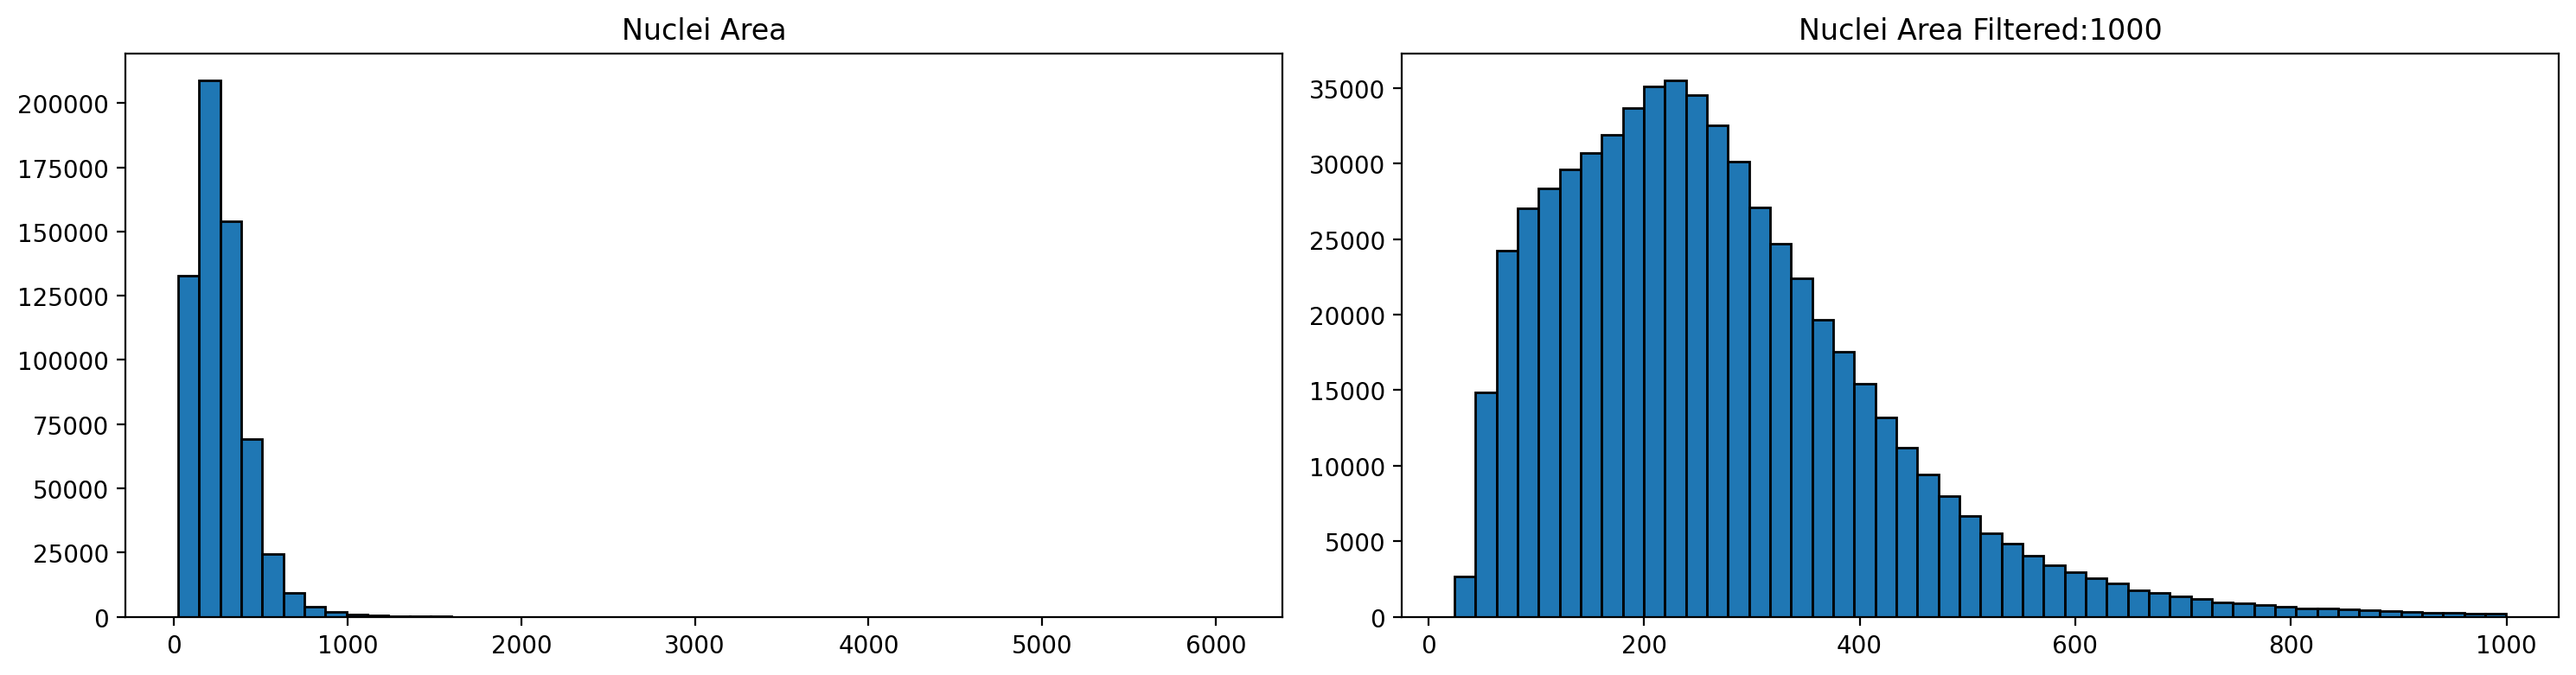

In [39]:
# Store the area of each nucleus in the GeoDataframe
gdf['area'] = gdf['geometry'].area

# Calculate quality control metrics for the original AnnData object
sc.pp.calculate_qc_metrics(grouped_filtered_adata, inplace=True)

# Plot the nuclei area distribution before and after filtering
plot_nuclei_area(gdf=gdf,area_cut_off=1000)

x-axis: nucleus area  
y-axis: no. of nuclei with that area

Based on the nuclei distribution we selected a value of 1000 to filter the data.

Next we plot the total UMI distribution.

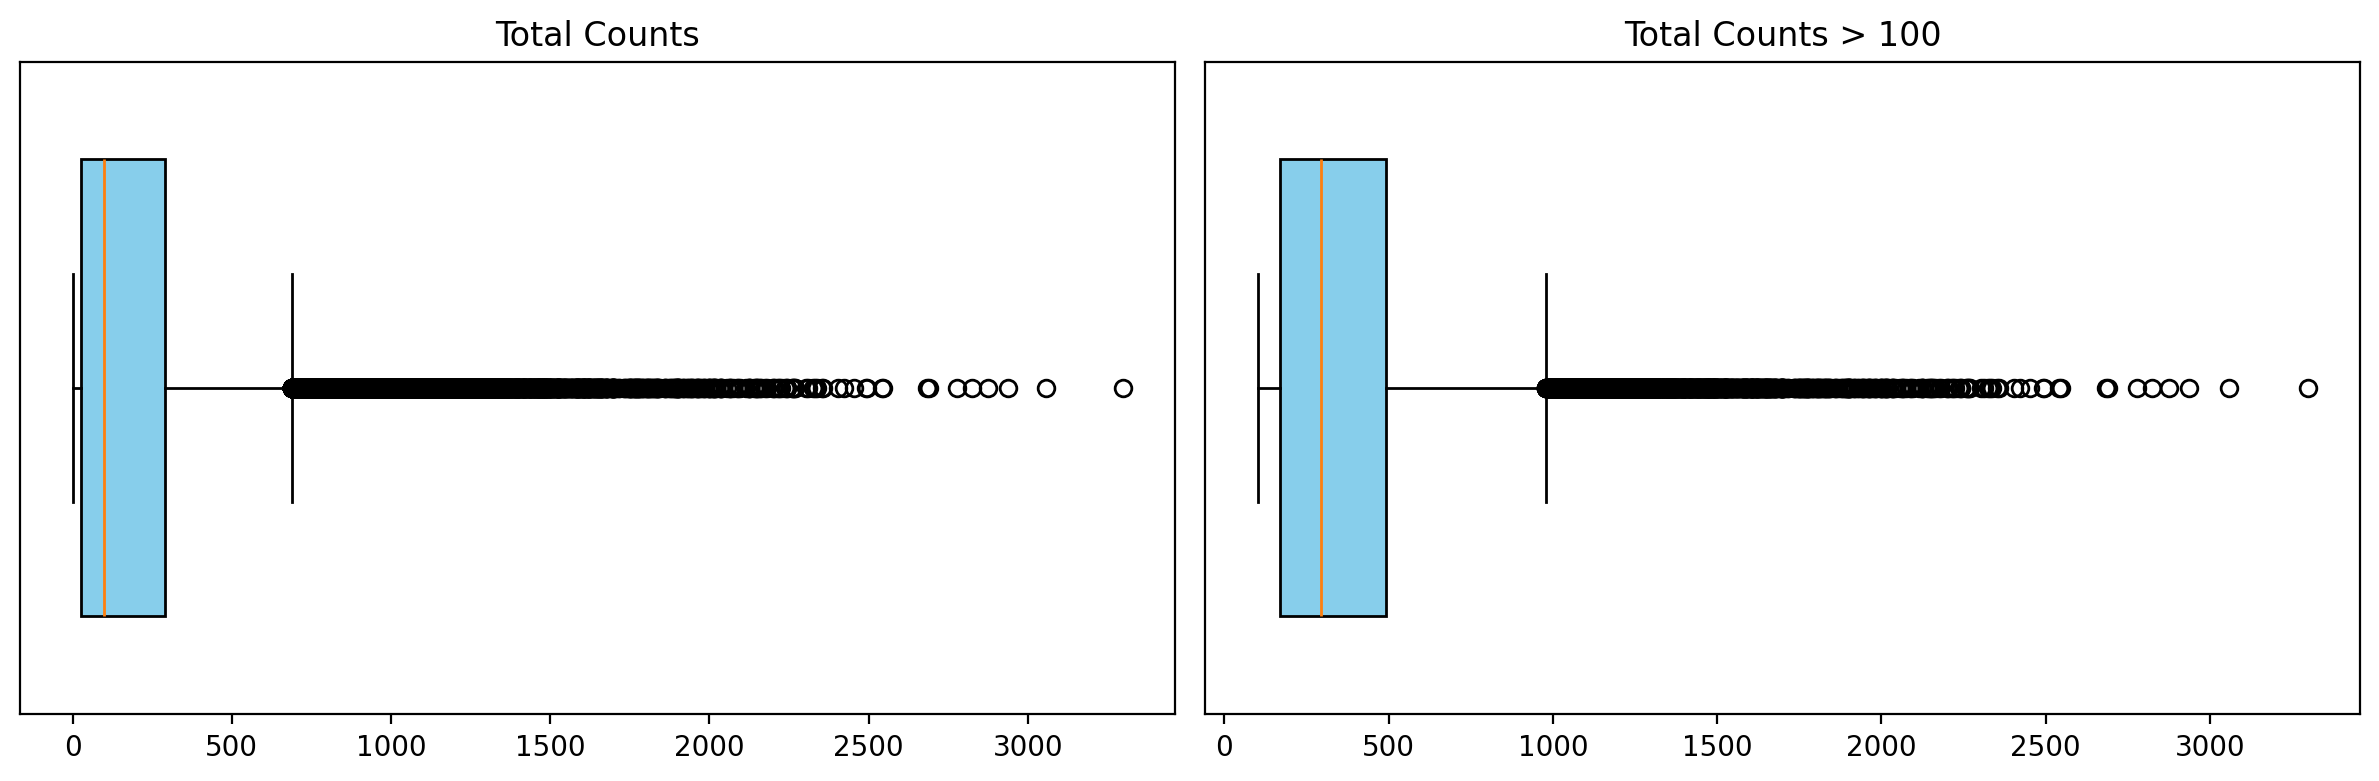

In [40]:
# Plot total UMI distribution
total_umi(grouped_filtered_adata, 100)

For this dataset, a total UMI cutoff of 100 was used. These values (nuclei area and UMI cutoff) may need adjustment for other datasets. 
Selecting appropriate cutoff values might require iteration based on the intepretation of the clustering results.

The following code block filters the data.

In [ ]:
# Create a mask based on the 'id' column for values present in 'gdf' with 'area' less than 500
mask_area = grouped_filtered_adata.obs['id'].isin(gdf[gdf['area'] < 500].id)

# Create a mask based on the 'total_counts' column for values greater than 100
mask_count = grouped_filtered_adata.obs['total_counts'] > 100

# Apply both masks to the original AnnData to create a new filtered AnnData object
count_area_filtered_adata = grouped_filtered_adata[mask_area & mask_count, :]

# Calculate quality control metrics for the filtered AnnData object
sc.pp.calculate_qc_metrics(count_area_filtered_adata, inplace=True)


_qc.py (140): Trying to modify attribute `.obs` of view, initializing view as actual.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


To assess the binning results, we examine gene expression and clustering. 
In the next block of code, the results undergo clustering. 
It is important to note that the resolution parameter used in Leiden clustering may need adjustment when working with different datasets.

In [42]:
# Normalize total counts for each cell in the AnnData object
sc.pp.normalize_total(count_area_filtered_adata, inplace=True)

# Logarithmize the values in the AnnData object after normalization
sc.pp.log1p(count_area_filtered_adata)

# Identify highly variable genes in the dataset using the Seurat method
sc.pp.highly_variable_genes(count_area_filtered_adata, flavor="seurat", n_top_genes=2000)

# Perform Principal Component Analysis (PCA) on the AnnData object
sc.pp.pca(count_area_filtered_adata)

# Build a neighborhood graph based on PCA components
sc.pp.neighbors(count_area_filtered_adata)

# Perform Leiden clustering on the neighborhood graph and store the results in 'clusters' column

# Adjust the resolution parameter as needed for different samples
sc.tl.leiden(count_area_filtered_adata, resolution=0.2, key_added="clusters")

`count_area_filtered_adata` now contains the clustering results for the nuclei that were left after filtering for large areas and UMI count under the set threshold:

In [43]:
# Create a GeoDataFrame with id and geometry
gdf_nuclei = gpd.GeoDataFrame(
    count_area_filtered_adata.obs[['id', 'geometry']].copy(),
    geometry='geometry'
)

# Save as Parquet
gdf_nuclei["Slide_ID"] = person
gdf_nuclei.to_parquet(os.path.join(dir_result_output, "nuclei_geometry.parquet"))
del gdf_nuclei

count_area_filtered_adata.obs = count_area_filtered_adata.obs.drop(columns=["geometry"])
count_area_filtered_adata.write(os.path.join(dir_result_output, "count_area_filtered_adata.h5ad"))

'count_area_filtered_adata.obs = count_area_filtered_adata.obs.drop(columns=["geometry"])\ncount_area_filtered_adata.write(os.path.join(dir_result_output, "count_area_filtered_adata.h5ad"))'

When the clustering results are plotted, we see clusters that align with morphological features.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


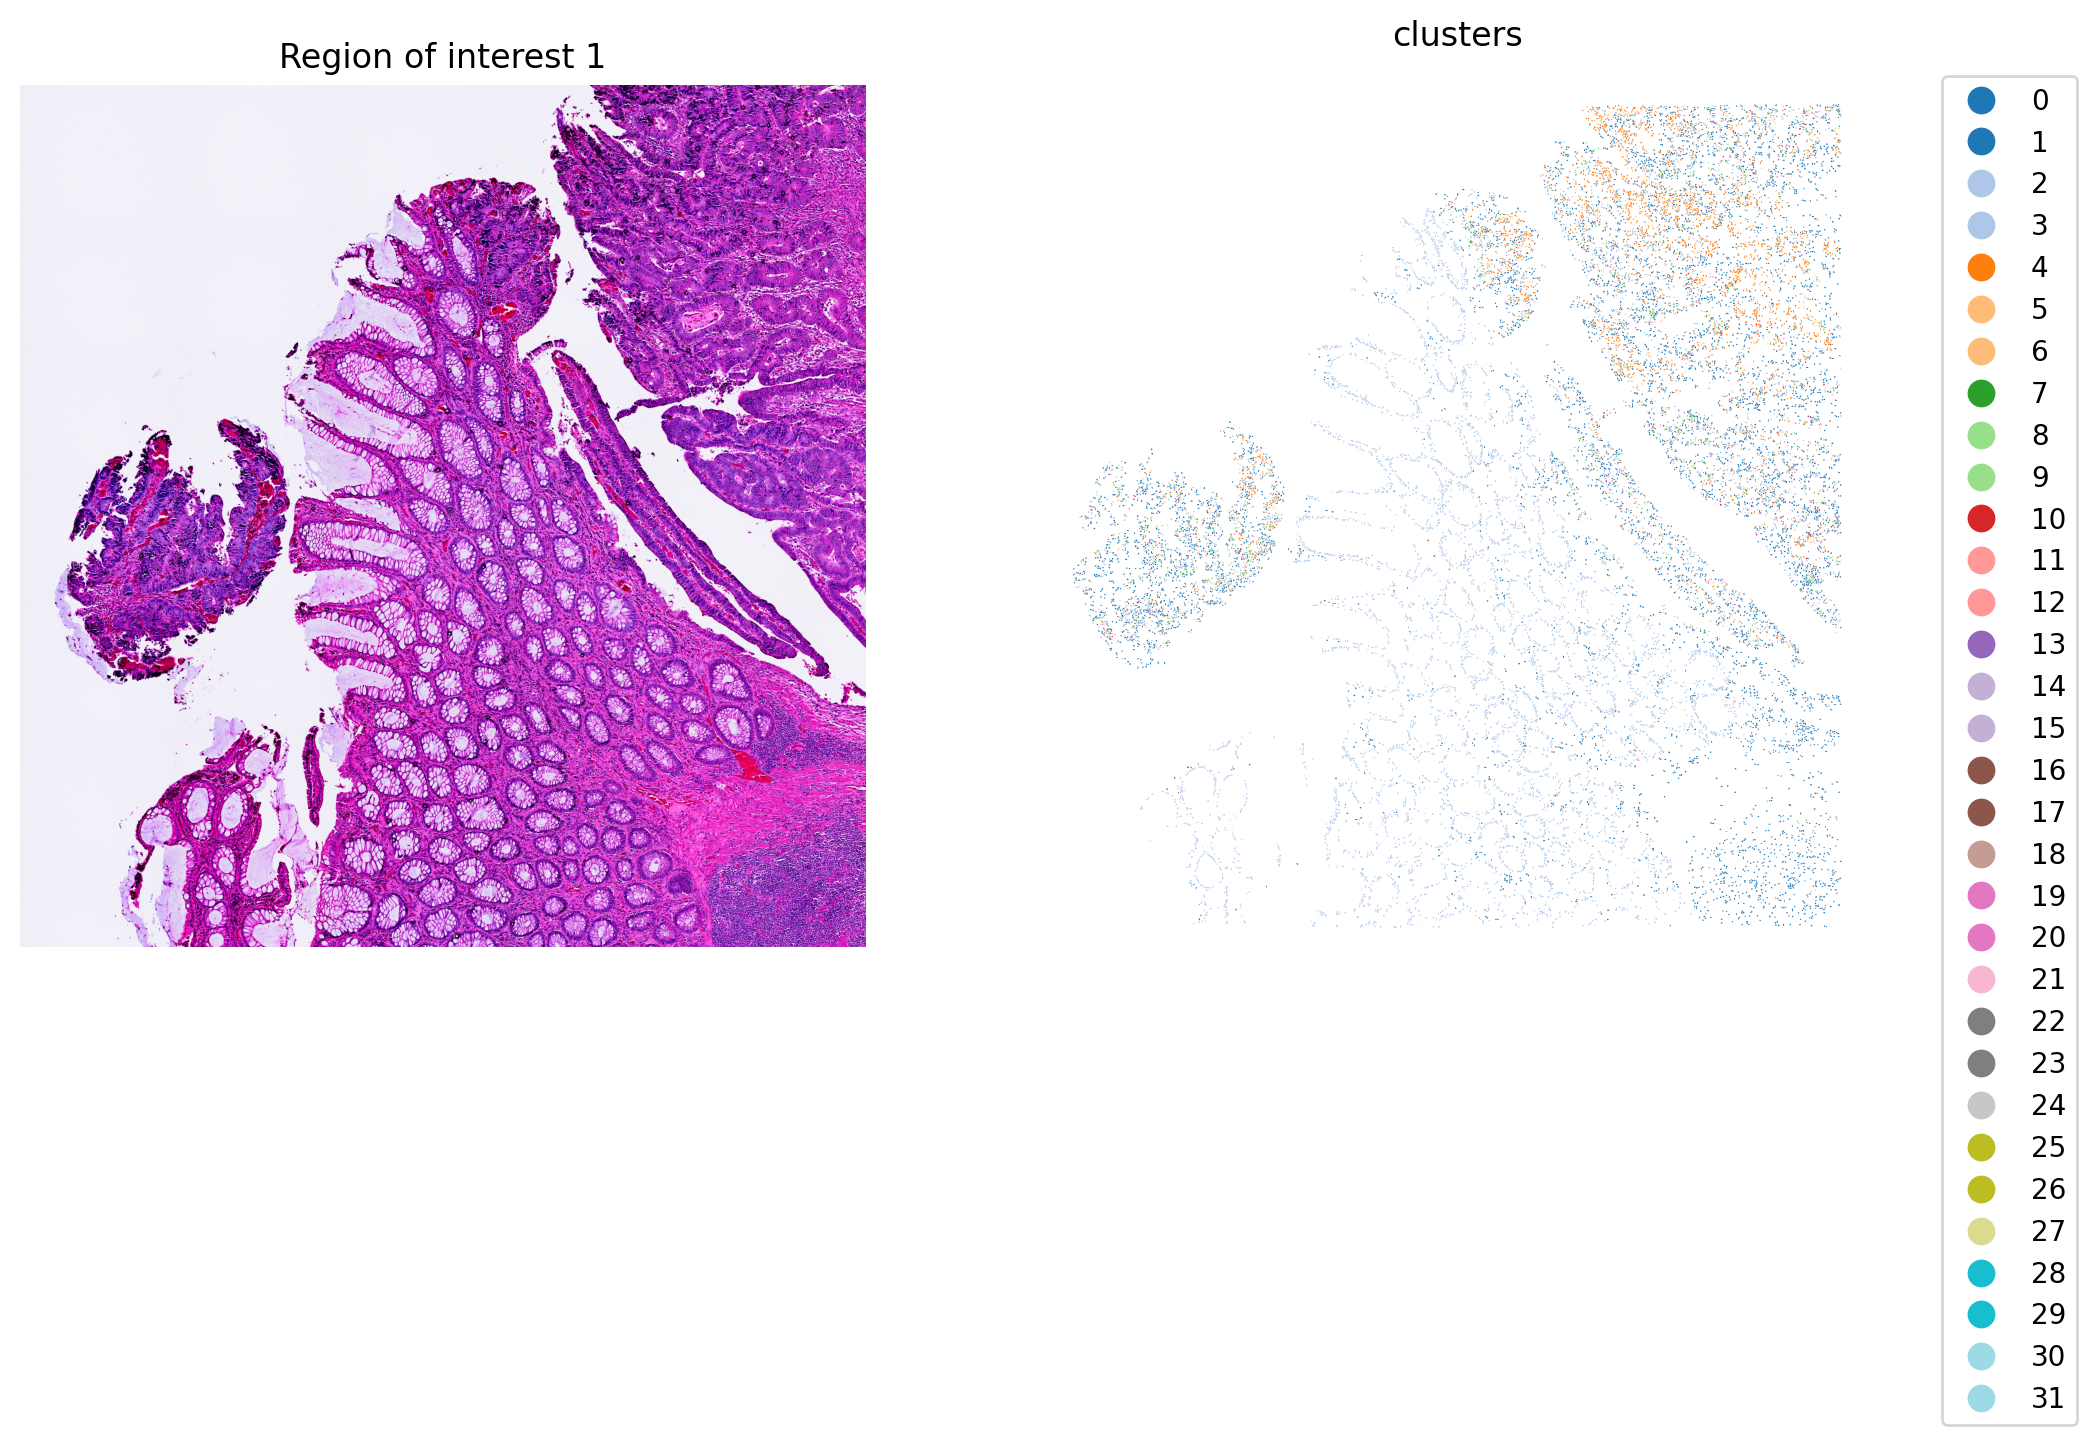

In [ ]:
# Plot and save the clustering results
plot_clusters_and_save_image(title="Region of interest 1", gdf=gdf, img=img, adata=count_area_filtered_adata, bbox=(x_min, x_max, y_min, y_max), color_by_obs='clusters', output_name=dir_result_output+"/image_clustering.ROI1.tiff")

## Merging the output
This step should be done after custom binning has been done for all samples.  
**Please make sure that only folders created by the cell segmentation/custom binning (equaling the samples) can be found in the corresponding output directory.**
This naming should also be consistent with the slide names and other instances where these names were used (e.g. patch creation).

Note: also be aware that currently the function does not assume any other parquet files other than the nuclei polygons. 


In [ ]:
import scanpy as sc
import anndata as ad
import os
import pandas as pd
import geopandas as gpd

adatas = []
people = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5"]
bin_size = "002um"
base_dir = "output"


def merge_anndatas(base_dir, filename="adata.h5ad", index_col=None, output_dir="output/merged_custom_binning/002um"):
    """
    Merge AnnData objects from folders in `base_dir`, adding slide_id column,
    and optionally using a specific column as the unique index.

    Parameters
    ----------
    base_dir : str
        Path to parent directory containing slide folders.
    filename : str
        Name of the AnnData file in each folder.
    index_col : str or None
        If None, uses adata.obs_names as the unique index.
        If str, uses this obs column to construct unique obs_names.

    Returns
    -------
    AnnData
        Merged AnnData object.
    """
    adatas = []

    for person in people:
        folder_path = os.path.join(base_dir, person)
        if not os.path.isdir(folder_path):
            continue
        
        file_path = os.path.join(folder_path, bin_size, "custom_binning", filename)
        if not os.path.exists(file_path):
            print(f"Skipping {folder_path}, file not found: {filename}")
            continue

        adata = sc.read_h5ad(file_path)
        if "Slide_ID" not in adata.obs.columns:
            adata.obs["Slide_ID"] = person

        # Construct unique obs_names
        if index_col is None:
            adata.obs_names = [f"{person}_{idx}" for idx in adata.obs_names]
        else:
            if index_col not in adata.obs.columns:
                raise ValueError(f"Column {index_col} not found in obs of {folder_path}")
            adata.obs_names = [f"{val}_{person}" for val in adata.obs[index_col]]

        # Ensure unique obs_names
        '''if not adata.obs_names.is_unique:
            print(f"Duplicate obs_names found in {file_path}")
            adata.obs_names = pd.Index([f"{name}_{i}" for i, name in enumerate(adata.obs_names)])

        # Ensure unique var_names
        if not adata.var_names.is_unique:
            print(f"Duplicate var_names found in {file_path}")
            adata.var_names = pd.Index([f"{name}_{i}" for i, name in enumerate(adata.var_names)])'''
        
        adata.var_names_make_unique()   
        adatas.append(adata)

    # Concatenate all AnnData objects
    adata_merged = ad.concat(adatas, join="outer", merge="first")

    os.makedirs(os.path.dirname(output_dir), exist_ok=True)
    adata_merged.write(os.path.join(output_dir, filename))

    return adata_merged


def merge_parquet(base_dir, filename="nuclei_geometry.parquet", output_dir="output/merged_custom_binning/002um"):
    parquet_nuclei_geometry_list = [] 

    for person in people:
        file_path = os.path.join(base_dir, person, bin_size, "custom_binning", filename)
        df_parquet = gpd.read_parquet(file_path)
        if "Slide_ID" not in df_parquet.columns:
            df_parquet["Slide_ID"] = person
        parquet_nuclei_geometry_list.append(df_parquet)

    os.makedirs(os.path.dirname(output_dir), exist_ok=True)

    parquet_nuclei_geometry_list = pd.concat(parquet_nuclei_geometry_list, ignore_index=True)
    parquet_nuclei_geometry_list.to_parquet(os.path.join(output_dir, "nuclei_geometry.parquet"), index=False)

    return parquet_nuclei_geometry_list



merged_nuclei_grouped_UMI_count = merge_anndatas(base_dir, filename="nuclei_grouped_UMI_count.h5ad", output_dir=f"output/merged_custom_binning/{bin_size}")
merged_custom_bins = merge_anndatas(base_dir, filename="filtered_custom_bins.h5ad", output_dir=f"output/merged_custom_binning/{bin_size}")
merged_count_area_filtered_adata = merge_anndatas(base_dir, filename="count_area_filtered_adata.h5ad", output_dir=f"output/merged_custom_binning/{bin_size}")
parquet_nuclei_geometry_list = merge_parquet(base_dir, filename="nuclei_geometry.parquet", output_dir=f"output/merged_custom_binning/{bin_size}")




/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSe